<a href="https://colab.research.google.com/github/Koroush-Mashayekh/diabetes-risk-prediction/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk Prediction: Exploratory Data Analysis

This notebook explores the Pima Indians Diabetes dataset to understand its structure, detect data quality issues and identify the most informative features.

**Next:** [`02_modeling.ipynb`](02_modeling.ipynb)

In [1]:
import pandas as pd
URL = "https://raw.githubusercontent.com/Koroush-Mashayekh/diabetes-risk-prediction/main/data/diabetes.csv"
df = pd.read_csv(URL)

print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 1. Data overview
Basic structure, data types, and summary statistics.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
cols_with_hidden_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI" ]
zero_counts = (df[cols_with_hidden_missing] == 0).sum()
zero_percent = (zero_counts/len(df) * 100).round(1)

pd.DataFrame({"zero_count" : zero_counts , "percent": zero_percent})

,zero_count,percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


### Key finding: hidden missing values
`df.info()` reports no null values, but several columns contain **zeros that are physiologically impossible**
(e.g. Glucose = 0, BMI = 0). These zeros represent missing measurements.

- **Insulin:** 48.7% missing
- **SkinThickness:** 29.6% missing
- **BloodPressure, BMI, Glucose:** < 5% missing

These zeros will be converted to `NaN` and imputed **inside the modeling pipeline** (after the train/test split) to avoid data leakage.

## 2. Target distribution
How many patients have diabetes vs. not?

Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    65.1
1    34.9
Name: count, dtype: float64


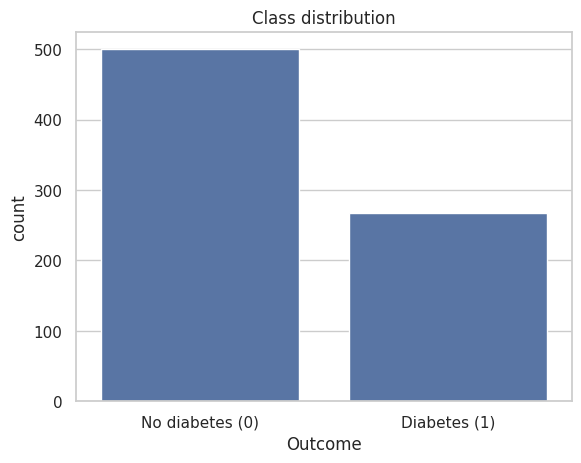

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid")
counts = df["Outcome"].value_counts()

print (counts)
print((counts/len(df) * 100).round(1))

ax = sns.countplot(data=df, x="Outcome")
ax.set_xticks([0, 1], labels=["No diabetes (0)", "Diabetes (1)"])
ax.set_title("Class distribution")
plt.show()

### Key finding: class imbalance
65.1% of patients have no diabetes, 34.9% have diabetes.
A naive model that always predicts "no diabetes" would reach **65% accuracy** while detecting zero patients.
Therefore, accuracy alone is misleading. We will focus on **ROC-AUC** and **Recall**,
and use **stratified** train/test splits to keep the class ratio the same in both sets.

## 3. Feature distributions by outcome
Zeros in medical columns are treated as missing (for visualization only).

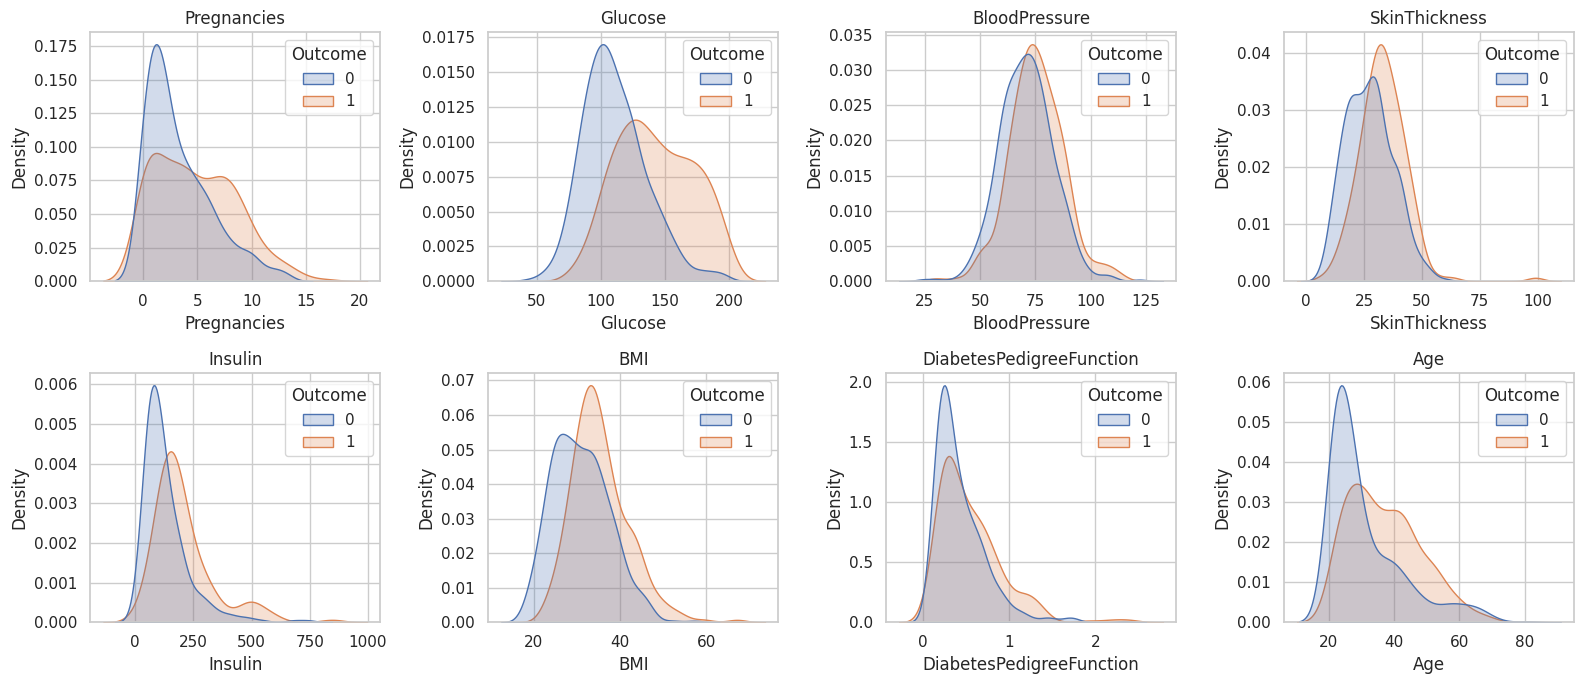

In [7]:
import numpy as np

df_plot = df.copy()
df_plot[cols_with_hidden_missing] = df_plot[cols_with_hidden_missing].replace(0, np.nan)

features = df.columns.drop("Outcome")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, col in zip(axes.flat, features):
    sns.kdeplot(data=df_plot, x=col, hue="Outcome",
                common_norm=False, fill=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Key findings: feature distributions
- **Glucose** shows the strongest separation between classes: diabetic patients have clearly higher values.
- **BMI, Age and Pregnancies** show moderate separation.
- **BloodPressure, SkinThickness and DiabetesPedigreeFunction** largely overlap between classes,
  suggesting weaker individual predictive power.

*Note: KDE curves slightly extend beyond the real data range (e.g. Age < 21) due to smoothing.*

## 4. Correlation analysis
Pearson correlation between features (zeros treated as missing).

In [8]:
corr = df_plot.corr()
corr["Outcome"].drop("Outcome").sort_values(ascending = False)

,Outcome
Glucose,0.494650
BMI,0.313680
Insulin,0.303454
SkinThickness,0.259491
Age,0.238356
Pregnancies,0.221898
DiabetesPedigreeFunction,0.173844
BloodPressure,0.170589


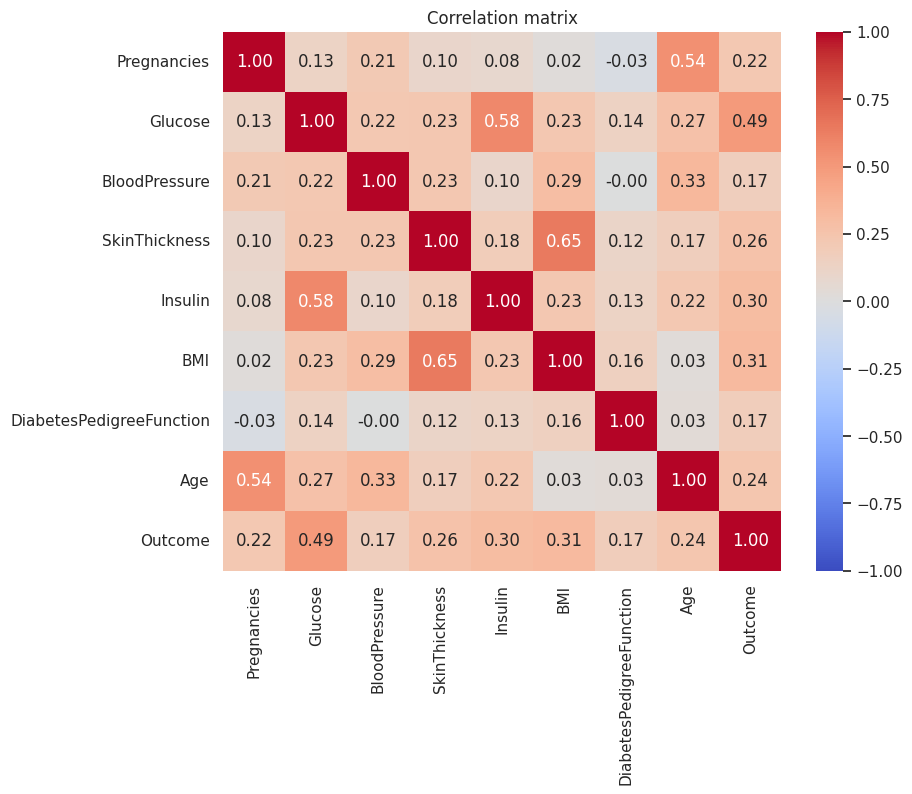

In [9]:
plt.figure(figsize = (9, 7))
sns.heatmap(corr, annot = True, fmt = ".2f", cmap = "coolwarm", vmin = -1, vmax = 1)
plt.title("Correlation matrix")
plt.show()

### Key findings: correlation
- Strongest correlations with Outcome: **Glucose (0.49)**, **BMI (0.31)**, **Insulin (0.30)**.
- Notable correlations between features, all physiologically plausible:
  - SkinThickness ↔ BMI (0.65): both reflect body fat
  - Glucose ↔ Insulin (0.58): insulin response to blood glucose
  - Pregnancies ↔ Age (0.54)
- No correlation exceeds 0.65, so multicollinearity is not severe and all features are kept.
- Pearson correlation only captures linear relationships; non-linear models may extract more information.

## 5. EDA summary
1. **Hidden missing values:** zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI are missing values
   (Insulin 48.7%, SkinThickness 29.6%). They will be imputed inside the modeling pipeline.
2. **Class imbalance:** 65% / 35%. A naive baseline reaches 65% accuracy, so we evaluate with ROC-AUC and Recall,
   using stratified splits.
3. **Most informative feature:** Glucose, followed by BMI, Insulin and Age.
4. **No severe multicollinearity:** all 8 features are kept.

**Next:** `02_modeling.ipynb`: baseline and model comparison.